# 07 · Statistical Analysis — how much of each difference is real?
**Group 7 · SQuAD v2 "Answer-or-Abstain" assistant**

Every comparison in notebooks 02–06 uses the same 200 questions. With 200 questions, a difference of 1–2 F1 points can be chance. This notebook adds the evidence a reader needs before trusting a conclusion:

1. **95% confidence intervals** for the headline metrics (bootstrap over questions)
2. **Paired tests** for the key comparisons — paired bootstrap for F1 and the exact McNemar test for per-question correctness
3. **Where the errors are**: performance by question type
4. **Does confidence separate right from wrong?** Reliability diagram, ECE and AUROC
5. **PEFT feasibility**: what LoRA fine-tuning would actually train (supports the adaptation decision)

It needs **no GPU and no model** — it only reads the saved result files in `results/`, so it runs in seconds and anyone can reproduce it.

In [1]:
import os, sys, json, re, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src.evaluate import score_rows, evaluate

rd = lambda p: pd.read_csv(p, keep_default_na=False)
systems = {
    "E1 baseline prompt":            rd("results/exp_prompt_baseline.csv"),
    "A few-shot, no harness":        rd("results/exp_prompt_few_shot.csv"),
    "B + validator & retry (E7)":    rd("results/E7_final_system.csv"),
    "C + fuzzy evidence (final)":    rd("results/ablation/C_fuzzy.csv"),
    "F Qwen-3B, no harness":         rd("results/ablation/F_qwen3b.csv"),
}
S = {k: score_rows(v).sort_values("id").reset_index(drop=True) for k, v in systems.items()}
ids = S["A few-shot, no harness"].id.tolist()
assert all(s.id.tolist() == ids for s in S.values()), "all systems must cover the same 200 questions"
RNG = np.random.default_rng(42); B = 5000
print(f"{len(S)} systems x {len(ids)} questions, {B} bootstrap resamples, seed 42")

5 systems x 200 questions, 5000 bootstrap resamples, seed 42


## 1 · 95% confidence intervals (bootstrap)
Resample the 200 questions with replacement 5,000 times and recompute each metric; the middle 95% of the results is the interval. Hallucination is computed on the 100 unanswerable questions and over-abstention on the 100 answerable ones, so those intervals are wider.

In [2]:
def metric_arrays(s):
    una, ans = ~s.is_answerable.values, s.is_answerable.values
    return {"F1_overall": s.f1.values * 100,
            "hallucination": np.where(una, s.pred_answerable.values.astype(float) * 100, np.nan),
            "over_abstention": np.where(ans, (~s.pred_answerable.values.astype(bool)).astype(float) * 100, np.nan)}

idx = RNG.integers(0, len(ids), size=(B, len(ids)))
rows = []
for name, s in S.items():
    r = {"system": name}
    for m, arr in metric_arrays(s).items():
        boot = np.nanmean(arr[idx], axis=1)
        r[m] = f"{np.nanmean(arr):.1f}  [{np.percentile(boot, 2.5):.1f}, {np.percentile(boot, 97.5):.1f}]"
    rows.append(r)
ci = pd.DataFrame(rows).set_index("system")
ci.to_csv("results/summary_confidence_intervals.csv"); ci

,F1_overall,hallucination,over_abstention
system,,,
E1 baseline prompt,"62.5 [56.1, 68.6]","51.0 [41.3, 61.2]","0.0 [0.0, 0.0]"
"A few-shot, no harness","77.0 [71.2, 82.4]","21.0 [13.3, 29.2]","17.0 [9.8, 25.0]"
B + validator & retry (E7),"74.0 [67.9, 79.8]","18.0 [10.8, 25.7]","29.0 [20.4, 38.5]"
C + fuzzy evidence (final),"75.8 [69.8, 81.3]","20.0 [12.5, 27.9]","21.0 [13.3, 29.5]"
"F Qwen-3B, no harness","72.6 [66.4, 78.4]","38.0 [28.4, 48.0]","5.0 [1.1, 9.8]"


## 2 · Paired comparisons
Both systems answer the **same** questions, so the right test is *paired*: resample questions and look at the difference on each resample. **McNemar's exact test** counts the questions only one system got right (b = only the first, c = only the second); if the two systems were equally good, b and c would be roughly equal.

In [3]:
from scipy.stats import binomtest

def compare(a, b, label):
    sa, sb = S[a], S[b]
    d = (sa.f1.values - sb.f1.values) * 100
    boot = d[idx].mean(axis=1)
    ra, rb = sa.em.values == 1, sb.em.values == 1
    only_a, only_b = int((ra & ~rb).sum()), int((~ra & rb).sum())
    p = binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return {"comparison": label, "F1 difference": round(d.mean(), 1),
            "95% CI": f"[{np.percentile(boot, 2.5):.1f}, {np.percentile(boot, 97.5):.1f}]",
            "P(diff > 0)": round((boot > 0).mean(), 3),
            "only first correct": only_a, "only second correct": only_b, "McNemar p": round(p, 4)}

pairs = [("A few-shot, no harness", "E1 baseline prompt", "few-shot prompt vs baseline prompt"),
         ("A few-shot, no harness", "B + validator & retry (E7)", "few-shot alone vs + validator (E7)"),
         ("C + fuzzy evidence (final)", "B + validator & retry (E7)", "fuzzy evidence vs strict validator"),
         ("A few-shot, no harness", "C + fuzzy evidence (final)", "few-shot alone vs final harness"),
         ("C + fuzzy evidence (final)", "F Qwen-3B, no harness", "1.5B + harness vs 3B without")]
paired = pd.DataFrame([compare(*p) for p in pairs]).set_index("comparison")
paired.to_csv("results/summary_paired_tests.csv"); paired

,F1 difference,95% CI,P(diff > 0),only first correct,only second correct,McNemar p
comparison,,,,,,
few-shot prompt vs baseline prompt,14.5,"[7.0, 21.8]",1.000,58,17,0.0000
few-shot alone vs + validator (E7),3.0,"[-0.1, 6.3]",0.971,5,3,0.7266
fuzzy evidence vs strict validator,1.7,"[-0.7, 4.3]",0.919,2,2,1.0000
few-shot alone vs final harness,1.2,"[-0.8, 3.5]",0.856,3,1,0.6250
1.5B + harness vs 3B without,3.2,"[-3.2, 9.6]",0.839,28,19,0.2430


In [4]:
# Hallucination specifically: 1.5B + harness vs 3B on the 100 unanswerable questions
c, f = S["C + fuzzy evidence (final)"], S["F Qwen-3B, no harness"]
una = ~c.is_answerable.values
hc, hf = c.pred_answerable.values[una].astype(bool), f.pred_answerable.values[una].astype(bool)
only_3b, only_c = int((hf & ~hc).sum()), int((hc & ~hf).sum())
p = binomtest(only_3b, only_3b + only_c, 0.5).pvalue
print(f"Unanswerable questions answered (hallucinated): 1.5B + harness {hc.sum()}, 3B {hf.sum()}")
print(f"Hallucinated only by 3B: {only_3b} | only by 1.5B + harness: {only_c} | McNemar exact p = {p:.4f}")

Unanswerable questions answered (hallucinated): 1.5B + harness 20, 3B 38
Hallucinated only by 3B: 21 | only by 1.5B + harness: 3 | McNemar exact p = 0.0003


**How to read this:** a 95% interval that excludes 0 (or McNemar p < 0.05) means the difference is unlikely to be chance on 200 questions. Intervals that include 0 mean "no detectable difference" — not "identical". Report both kinds honestly.

## 3 · Where are the errors? Performance by question type
The question's first word (who / what / when / ...) is a rough proxy for the kind of answer expected. Groups with fewer than ~10 questions are too small to draw conclusions from; they are shown for completeness.

In [5]:
def qtype(q):
    q = q.strip().lower()
    for t in ["how many", "how much", "who", "when", "where", "which", "why", "how", "what"]:
        if q.startswith(t) or re.search(rf"\b{t}\b", q[:40]):
            return t
    return "other"

short = {"A few-shot, no harness": "A", "C + fuzzy evidence (final)": "C final", "F Qwen-3B, no harness": "F 3B"}
base = S["A few-shot, no harness"].assign(qtype=S["A few-shot, no harness"].question.map(qtype))
by_type = base.groupby("qtype").agg(n=("id", "size"), answerable=("is_answerable", "sum"))
for name, tag in short.items():
    s = S[name].assign(qtype=S[name].question.map(qtype))
    by_type[f"F1 answerable ({tag})"] = s[s.is_answerable].groupby("qtype").f1.mean().mul(100).round(1)
    by_type[f"hallucination % ({tag})"] = s[~s.is_answerable].groupby("qtype").pred_answerable.mean().mul(100).round(1)
by_type = by_type.sort_values("n", ascending=False)
by_type.to_csv("results/summary_by_question_type.csv"); by_type

,n,answerable,F1 answerable (A),hallucination % (A),F1 answerable (C final),hallucination % (C final),F1 answerable (F 3B),hallucination % (F 3B)
qtype,,,,,,,,
what,126,59,73.3,20.9,71.7,20.9,83.9,40.3
other,18,11,62.1,42.9,57.5,28.6,66.9,57.1
when,15,9,82.2,16.7,71.1,16.7,87.7,0.0
who,13,4,100.0,11.1,100.0,11.1,95.8,44.4
which,9,6,77.8,33.3,77.8,33.3,77.8,33.3
where,8,4,100.0,25.0,75.0,25.0,100.0,25.0
how,6,3,73.9,0.0,73.9,0.0,63.4,33.3
how many,3,3,55.6,NaN,55.6,NaN,100.0,NaN
how much,2,1,100.0,0.0,100.0,0.0,100.0,0.0


## 4 · Does confidence separate right from wrong?
Confidence = geometric-mean probability of the decision tokens (`src/confidence.py`). Two questions: is it **calibrated** (when it says 0.8, is it right ~80% of the time?) and does it **discriminate** (AUROC: the chance a random correct answer gets higher confidence than a random wrong one; 0.5 = no better than a coin).

answered questions: 99 | ECE = 0.215 | AUROC = 0.675
mean confidence: correct 0.870 vs wrong 0.816


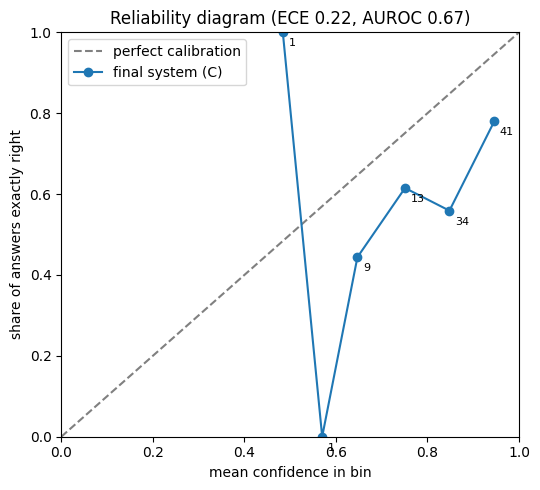

,bin,n,mean confidence,accuracy
0,0.4-0.5,1,0.484,1.000
1,0.5-0.6,1,0.570,0.000
2,0.6-0.7,9,0.647,0.444
3,0.7-0.8,13,0.751,0.615
4,0.8-0.9,34,0.848,0.559
5,0.9-1.0,41,0.946,0.780


In [6]:
c = S["C + fuzzy evidence (final)"].copy()
c["conf"] = pd.to_numeric(c.confidence, errors="coerce")
answered = c[c.pred_answerable.astype(bool) & c.conf.notna()].copy()
answered["right"] = answered.em == 1

def auroc(scores, labels):
    pos, neg = scores[labels], scores[~labels]
    return float(np.mean([(p > n) + 0.5 * (p == n) for p in pos for n in neg]))

bins = np.linspace(0, 1, 11); rows, ece = [], 0.0
for lo, hi in zip(bins[:-1], bins[1:]):
    g = answered[(answered.conf >= lo) & (answered.conf < hi if hi < 1 else answered.conf <= hi)]
    if len(g):
        rows.append({"bin": f"{lo:.1f}-{hi:.1f}", "n": len(g), "mean confidence": round(g.conf.mean(), 3), "accuracy": round(g.right.mean(), 3)})
        ece += len(g) / len(answered) * abs(g.conf.mean() - g.right.mean())
rel = pd.DataFrame(rows)
a = auroc(answered.conf.values, answered.right.values)
print(f"answered questions: {len(answered)} | ECE = {ece:.3f} | AUROC = {a:.3f}")
print(f"mean confidence: correct {answered[answered.right].conf.mean():.3f} vs wrong {answered[~answered.right].conf.mean():.3f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
ax.plot(rel["mean confidence"], rel["accuracy"], "o-", label="final system (C)")
for _, r in rel.iterrows():
    ax.annotate(str(r.n), (r["mean confidence"], r["accuracy"]), textcoords="offset points", xytext=(4, -10), fontsize=8)
ax.set_xlabel("mean confidence in bin"); ax.set_ylabel("share of answers exactly right"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title(f"Reliability diagram (ECE {ece:.2f}, AUROC {a:.2f})"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig("results/reliability_diagram.png", dpi=200); plt.show()
rel.to_csv("results/summary_reliability.csv", index=False); rel

## 5 · PEFT feasibility: what would LoRA fine-tuning train?
Requirement 8 asks for prompting vs RAG vs fine-tuning/PEFT. The numbers below come from Qwen2.5-1.5B-Instruct's configuration. LoRA freezes the model and learns, for each chosen weight matrix W (d_out × d_in), two small matrices A (r × d_in) and B (d_out × r) — so r × (d_in + d_out) new parameters per matrix.

In [7]:
cfg = dict(layers=28, hidden=1536, heads=12, kv_heads=2, head_dim=128, intermediate=8960, vocab=151936)
kv = cfg["kv_heads"] * cfg["head_dim"]                       # 256: grouped-query attention
mats = {"q_proj": (cfg["hidden"], cfg["hidden"]), "k_proj": (cfg["hidden"], kv), "v_proj": (cfg["hidden"], kv),
        "o_proj": (cfg["hidden"], cfg["hidden"]), "gate_proj": (cfg["hidden"], cfg["intermediate"]),
        "up_proj": (cfg["hidden"], cfg["intermediate"]), "down_proj": (cfg["intermediate"], cfg["hidden"])}
per_layer = sum(i * o for i, o in mats.values())
total = cfg["layers"] * per_layer + cfg["vocab"] * cfg["hidden"]   # embeddings (tied with the LM head)
print(f"model weights (approx.): {total / 1e9:.2f} B parameters")

rows = []
for r in (8, 16):
    for targets in (["q_proj", "v_proj"], list(mats)):
        n = cfg["layers"] * sum(r * (mats[m][0] + mats[m][1]) for m in targets)
        rows.append({"rank r": r, "matrices adapted": ", ".join(targets) if len(targets) < 3 else "all 7 linear layers",
                     "trainable parameters": f"{n:,}", "% of model": f"{100 * n / total:.3f}%",
                     "adapter size (fp16)": f"{n * 2 / 1e6:.1f} MB"})
peft = pd.DataFrame(rows); peft.to_csv("results/summary_peft_feasibility.csv", index=False); peft

model weights (approx.): 1.54 B parameters


,rank r,matrices adapted,trainable parameters,% of model,adapter size (fp16)
0,8,"q_proj, v_proj","1,089,536",0.071%,2.2 MB
1,8,all 7 linear layers,"9,232,384",0.598%,18.5 MB
2,16,"q_proj, v_proj","2,179,072",0.141%,4.4 MB
3,16,all 7 linear layers,"18,464,768",1.196%,36.9 MB


**Use in the report (adaptation decision):** LoRA is *cheap* here (well under 1% of the weights, a few MB of adapter), so cost is not the reason to skip it. The reasons are the evidence: (1) the knowledge is in the supplied paragraph, not missing from the model; (2) the remaining errors are *behavioural* — 19 of 21 hallucinations quote real sentences from adversarial "trap" questions (notebook 06 §2), which a classifier-like abstention signal trained on SQuAD v2's train split could address; (3) the harness already guarantees format and grounding. So: prompting + harness now, RAG when no document is supplied, and LoRA on the train split as the most promising next step for abstention — training on train, evaluating on our frozen validation subset to avoid leakage.